Cell 1 – Import libraries and load dataset
We will use PySpark for Parquet loading and data validation, then transfer the small modelling dataset to Pandas for Scikit-learn.

In [3]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)
from sklearn.utils.class_weight import compute_sample_weight

# 1. Automatically locate project root
PROJECT_ROOT = Path.cwd()

while not (
    PROJECT_ROOT / "for1sight_warehouse"
).exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Cannot locate For1Sight project root. "
            "Check your VS Code working directory."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent

# 2. Define dataset location
DATASET_PATH = (
    PROJECT_ROOT
    / "for1sight_warehouse"
    / "prediction_training_v2_8_prerace.parquet"
)

# 3. Define model output folder
MODEL_DIR = PROJECT_ROOT / "models" / "v2_8"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 4. Verify dataset exists
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Parquet dataset not found: {DATASET_PATH}"
    )

# 5. Initialise Spark
spark = (
    SparkSession.builder
    .appName("For1Sight_V2_8_Model_Training")
    .master("local[*]")
    .getOrCreate()
)

# 6. Load Parquet dataset
df_spark = spark.read.parquet(str(DATASET_PATH))

print("\nPySpark version:", spark.version)
print("Dataset records:", df_spark.count())

df_spark.printSchema()

# 7. Convert to Pandas
df = df_spark.toPandas()

print("\nPandas dataset shape:", df.shape)
print("Dataset loaded successfully!")


Project root: c:\Users\ayepd\Desktop\For1Sight Project
Dataset path: c:\Users\ayepd\Desktop\For1Sight Project\for1sight_warehouse\prediction_training_v2_8_prerace.parquet
Dataset exists: True

PySpark version: 3.5.9
Dataset records: 1309
root
 |-- dataset_version: string (nullable = true)
 |-- year: long (nullable = true)
 |-- round: integer (nullable = true)
 |-- event_date: string (nullable = true)
 |-- event_name: string (nullable = true)
 |-- event_norm: string (nullable = true)
 |-- driver_code: string (nullable = true)
 |-- driver_code_norm: string (nullable = true)
 |-- constructor: string (nullable = true)
 |-- starting_grid: double (nullable = true)
 |-- finishing_position: integer (nullable = true)
 |-- is_winner: integer (nullable = true)
 |-- race_points: integer (nullable = true)
 |-- race_status: string (nullable = true)
 |-- event_prediction_ready: boolean (nullable = true)
 |-- model_training_eligible: boolean (nullable = true)
 |-- target: integer (nullable = true)
 |-

Cell 2 – Define features and validate the dataset

In [4]:

# CELL 2: DATASET VALIDATION

# 1. Define model features

NUMERIC_FEATURES = [
    "starting_grid",
    "driver_prior_avg_finish_3",
    "driver_prior_avg_points_3",
    "driver_circuit_prior_avg_finish",
    "driver_circuit_prior_starts",
    "constructor_prior_avg_finish_3",
    "constructor_prior_avg_points_3",
    "constructor_circuit_prior_avg_finish",
    "constructor_circuit_prior_starts"
]

CATEGORICAL_FEATURES = [
    "driver_code_norm",
    "constructor",
    "event_norm"
]

FEATURE_COLUMNS = (
    NUMERIC_FEATURES + CATEGORICAL_FEATURES
)

TARGET = "target"
GROUP = "event_id"

# 2. Verify required columns

required_columns = (
    FEATURE_COLUMNS
    + [
        TARGET,
        GROUP,
        "year",
        "event_date",
        "model_training_eligible",
        "event_prediction_ready"
    ]
)

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("All required columns are available.")

# 3. Check dataset structure

print("\nDataset shape:", df.shape)

print("\nSeason distribution:")
print(df["year"].value_counts().sort_index())

# 4. Check training eligibility

print("\nTraining eligibility:")
print(df["model_training_eligible"].value_counts(
    dropna=False
))

print("\nEvent prediction readiness:")
print(df["event_prediction_ready"].value_counts(
    dropna=False
))

# 5. Check target distribution

print("\nTarget distribution:")
print(df[TARGET].value_counts(dropna=False))

# 6. Check missing feature values

print("\nMissing feature values:")
print(
    df[FEATURE_COLUMNS]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

# 7. Check duplicate driver-event records

duplicates = df.duplicated(
    subset=["year", GROUP, "driver_code_norm"],
    keep=False
)

print("\nDuplicate driver-event records:", duplicates.sum())

if duplicates.any():
    print(
        df.loc[
            duplicates,
            ["year", GROUP, "driver_code_norm"]
        ]
    )

# 8. Check winner count per race

race_check = (
    df.groupby(["year", GROUP])
    .agg(
        driver_records=(TARGET, "size"),
        winner_count=(TARGET, "sum")
    )
    .reset_index()
)

print("\nRace winner validation:")
print(race_check["winner_count"].value_counts())

invalid_races = race_check[
    race_check["winner_count"] != 1
]

print("\nRaces without exactly one winner:",
      len(invalid_races))

# 9. Validate target values

print("\nUnique target values:", sorted(
    df[TARGET].dropna().unique()
))

# 10. Final validation summary

print("\n========== VALIDATION SUMMARY ==========")

print("Total records:", len(df))

print("Unique races:", df[GROUP].nunique())

print("Unique seasons:", sorted(df["year"].unique()))

print("Duplicate records:", duplicates.sum())

print("Invalid winner races:", len(invalid_races))

print("========================================")


All required columns are available.

Dataset shape: (1309, 26)

Season distribution:
year
2024    478
2025    479
2026    352
Name: count, dtype: int64

Training eligibility:
model_training_eligible
True    1309
Name: count, dtype: int64

Event prediction readiness:
event_prediction_ready
True    1309
Name: count, dtype: int64

Target distribution:
target
0    1245
1      64
Name: count, dtype: int64

Missing feature values:
driver_circuit_prior_avg_finish         648
constructor_circuit_prior_avg_finish    560
driver_prior_avg_points_3                28
driver_prior_avg_finish_3                28
constructor_prior_avg_points_3           24
constructor_prior_avg_finish_3           24
starting_grid                             0
driver_circuit_prior_starts               0
constructor_circuit_prior_starts          0
driver_code_norm                          0
constructor                               0
event_norm                                0
dtype: int64

Duplicate driver-event record

Cell 3 – Build the three machine-learning pipelines

In [8]:

# ============================================================
# CELL 3: BUILD MACHINE LEARNING PIPELINES
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# ------------------------------------------------------------
# 1. CREATE NUMERIC PREPROCESSING
# ------------------------------------------------------------

def create_numeric_pipeline(scale=False):

    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True
            )
        )
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler())
        )

    return Pipeline(steps)


# ------------------------------------------------------------
# 2. CREATE CATEGORICAL PREPROCESSING
# ------------------------------------------------------------

def create_categorical_pipeline():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])


# ------------------------------------------------------------
# 3. CREATE COMPLETE PREPROCESSOR
# ------------------------------------------------------------

def create_preprocessor(scale_numeric=False):

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                create_numeric_pipeline(
                    scale=scale_numeric
                ),
                NUMERIC_FEATURES
            ),
            (
                "categorical",
                create_categorical_pipeline(),
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop"
    )


# ------------------------------------------------------------
# 4. DEFINE LOGISTIC REGRESSION
# ------------------------------------------------------------

logistic_regression = Pipeline([
    (
        "preprocessor",
        create_preprocessor(scale_numeric=True)
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])


# ------------------------------------------------------------
# 5. DEFINE RANDOM FOREST
# ------------------------------------------------------------

random_forest = Pipeline([
    (
        "preprocessor",
        create_preprocessor(scale_numeric=False)
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])


# ------------------------------------------------------------
# 6. DEFINE GRADIENT BOOSTING
# ------------------------------------------------------------

gradient_boosting = Pipeline([
    (
        "preprocessor",
        create_preprocessor(scale_numeric=False)
    ),
    (
        "classifier",
        GradientBoostingClassifier(
            n_estimators=80,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=5,
            random_state=42
        )
    )
])


# ------------------------------------------------------------
# 7. REGISTER THREE MODELS
# ------------------------------------------------------------

models = {

    "Logistic Regression": logistic_regression,

    "Random Forest": random_forest,

    "Gradient Boosting": gradient_boosting

}

print("======================================")
print("FOR1SIGHT V2.8 - MODEL PIPELINES")
print("======================================")

for model_name, model in models.items():

    print(f"\n{model_name}")
    print(model)

print("\nAll three model pipelines created successfully.")


FOR1SIGHT V2.8 - MODEL PIPELINES

Logistic Regression
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['starting_grid',
                                                   'driver_prior_avg_finish_3',
                                                   'driver_prior_avg_points_3',
                                                   'driver_circuit_prior_avg_finish',
                                                   'driver_circuit_prior_starts',
    

Cell 4 – Prepare chronological datasets

In [6]:

# ============================================================
# CELL 4: CHRONOLOGICAL DATA SEPARATION
# ============================================================

# 1. Training dataset - 2024
train_df = df[
    (df["year"] == 2024) &
    (df["model_training_eligible"] == True)
].copy()

# 2. Validation dataset - 2025
validation_df = df[
    (df["year"] == 2025) &
    (df["model_training_eligible"] == True)
].copy()

# 3. Verify the datasets
assert len(train_df) == 478
assert len(validation_df) == 479

assert train_df["event_id"].nunique() == 24
assert validation_df["event_id"].nunique() == 24

assert set(train_df["year"].unique()) == {2024}
assert set(validation_df["year"].unique()) == {2025}

# 4. Prepare training features and target
X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df[TARGET].copy()

# 5. Prepare validation features and target
X_val = validation_df[FEATURE_COLUMNS].copy()
y_val = validation_df[TARGET].copy()

# 6. Prepare event grouping for training
groups_train = train_df["event_id"].copy()

# 7. Display summary
print("=" * 55)
print("FOR1SIGHT V2.8 - CHRONOLOGICAL DATA SPLIT")
print("=" * 55)

print("\nTRAINING DATA - 2024")
print("Records:", len(X_train))
print("Events:", train_df["event_id"].nunique())
print("Winners:", y_train.sum())

print("\nVALIDATION DATA - 2025")
print("Records:", len(X_val))
print("Events:", validation_df["event_id"].nunique())
print("Winners:", y_val.sum())

print("\nFINAL TEST DATA - 2026")
print("Reserved for Stage 4.")
print("Not used during model training or selection.")

print("\nFeature count:", len(FEATURE_COLUMNS))

print("\nChronological separation successful.")


FOR1SIGHT V2.8 - CHRONOLOGICAL DATA SPLIT

TRAINING DATA - 2024
Records: 478
Events: 24
Winners: 24

VALIDATION DATA - 2025
Records: 479
Events: 24
Winners: 24

FINAL TEST DATA - 2026
Reserved for Stage 4.
Not used during model training or selection.

Feature count: 12

Chronological separation successful.


Cell 5 – Train the three models

In [9]:

# ============================================================
# CELL 5: TRAIN THREE MACHINE LEARNING MODELS
# ============================================================

from sklearn.utils.class_weight import compute_sample_weight
from pathlib import Path
import joblib
import json

# ------------------------------------------------------------
# 1. CREATE MODEL OUTPUT DIRECTORY
# ------------------------------------------------------------

MODEL_DIR = PROJECT_ROOT / "models" / "v2_8"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. PREPARE GRADIENT BOOSTING SAMPLE WEIGHTS
# ------------------------------------------------------------

gb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Training records:", len(X_train))
print("Winner records:", int(y_train.sum()))
print("Non-winner records:", int((y_train == 0).sum()))

# ------------------------------------------------------------
# 3. TRAIN LOGISTIC REGRESSION
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 55)

models["Logistic Regression"].fit(
    X_train,
    y_train
)

print("Logistic Regression training completed.")

# ------------------------------------------------------------
# 4. TRAIN RANDOM FOREST
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("TRAINING RANDOM FOREST")
print("=" * 55)

models["Random Forest"].fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

# ------------------------------------------------------------
# 5. TRAIN GRADIENT BOOSTING
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("TRAINING GRADIENT BOOSTING")
print("=" * 55)

models["Gradient Boosting"].fit(
    X_train,
    y_train,
    classifier__sample_weight=gb_sample_weights
)

print("Gradient Boosting training completed.")

# ------------------------------------------------------------
# 6. SAVE TRAINED MODELS
# ------------------------------------------------------------

saved_models = {}

for model_name, model in models.items():

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + "_v2_8.joblib"
    )

    model_path = MODEL_DIR / filename

    joblib.dump(model, model_path)

    saved_models[model_name] = str(model_path)

    print(f"\nSaved {model_name}:")
    print(model_path)

# ------------------------------------------------------------
# 7. TRAINING SUMMARY
# ------------------------------------------------------------

training_summary = {
    "project": "For1Sight",
    "version": "V2.8",
    "training_season": 2024,
    "training_records": len(X_train),
    "training_events": train_df["event_id"].nunique(),
    "feature_count": len(FEATURE_COLUMNS),
    "target": TARGET,
    "models": list(models.keys()),
    "saved_models": saved_models,
    "validation_season": 2025,
    "final_test_season": 2026
}

summary_path = (
    MODEL_DIR / "stage3_training_summary.json"
)

summary_path.write_text(
    json.dumps(training_summary, indent=4),
    encoding="utf-8"
)

print("\n" + "=" * 55)
print("FOR1SIGHT V2.8 - TRAINING COMPLETED")
print("=" * 55)

print("Models trained:", len(models))
print("Models saved:", len(saved_models))
print("2026 remains untouched.")


Training records: 478
Winner records: 24
Non-winner records: 454

TRAINING LOGISTIC REGRESSION
Logistic Regression training completed.

TRAINING RANDOM FOREST
Random Forest training completed.

TRAINING GRADIENT BOOSTING
Gradient Boosting training completed.

Saved Logistic Regression:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\logistic_regression_v2_8.joblib

Saved Random Forest:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\random_forest_v2_8.joblib

Saved Gradient Boosting:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\gradient_boosting_v2_8.joblib

FOR1SIGHT V2.8 - TRAINING COMPLETED
Models trained: 3
Models saved: 3
2026 remains untouched.


Cell 6 – Generate 2025 predictions

In [10]:

# ============================================================
# CELL 6: GENERATE 2025 VALIDATION PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd

validation_predictions = {}

for model_name, model in models.items():

    print(f"Generating predictions: {model_name}")

    probabilities = model.predict_proba(X_val)[:, 1]

    validation_predictions[model_name] = probabilities

    print("Predictions generated:", len(probabilities))

print("\nAll three models have generated 2025 predictions.")

# Create a prediction dataframe for each model

prediction_results = validation_df[
    [
        "year",
        "round",
        "event_id",
        "event_name",
        "driver_code",
        "starting_grid",
        "target"
    ]
].copy()

for model_name, probabilities in validation_predictions.items():

    column_name = (
        model_name.lower().replace(" ", "_")
        + "_probability"
    )

    prediction_results[column_name] = probabilities

display(prediction_results.head(10))


Generating predictions: Logistic Regression
Predictions generated: 479
Generating predictions: Random Forest
Predictions generated: 479
Generating predictions: Gradient Boosting
Predictions generated: 479

All three models have generated 2025 predictions.


,year,round,event_id,event_name,driver_code,starting_grid,target,logistic_regression_probability,random_forest_probability,gradient_boosting_probability
478,2025,1,2025_australiangrandprix,Australian Grand Prix,NOR,1.0,1,0.777150,0.618060,0.881590
479,2025,1,2025_australiangrandprix,Australian Grand Prix,PIA,2.0,0,0.508465,0.468324,0.373349
480,2025,1,2025_australiangrandprix,Australian Grand Prix,VER,3.0,0,0.944081,0.697908,0.842753
481,2025,1,2025_australiangrandprix,Australian Grand Prix,RUS,4.0,0,0.695248,0.718298,0.716431
482,2025,1,2025_australiangrandprix,Australian Grand Prix,TSU,5.0,0,0.045909,0.063860,0.038684
483,2025,1,2025_australiangrandprix,Australian Grand Prix,ALB,6.0,0,0.014365,0.019502,0.023893
484,2025,1,2025_australiangrandprix,Australian Grand Prix,LEC,7.0,0,0.524016,0.474716,0.254666
485,2025,1,2025_australiangrandprix,Australian Grand Prix,HAM,8.0,0,0.265833,0.278951,0.011789
486,2025,1,2025_australiangrandprix,Australian Grand Prix,GAS,9.0,0,0.014201,0.020672,0.023893
487,2025,1,2025_australiangrandprix,Australian Grand Prix,SAI,10.0,0,0.128030,0.317100,0.638853


Cell 7 – Evaluate race winner predictions
This is one of our most important evaluations.

Instead of simply checking individual driver records, we rank the drivers within each Grand Prix based on their predicted scores.

The driver with the highest score becomes the model's predicted winner.

In [11]:

# ============================================================
# CELL 7: RACE-LEVEL WINNER EVALUATION
# ============================================================

race_metrics = []

race_prediction_details = {}

for model_name in models.keys():

    probability_column = (
        model_name.lower().replace(" ", "_")
        + "_probability"
    )

    records = []

    for event_id, race in prediction_results.groupby("event_id"):

        ranked = race.sort_values(
            probability_column,
            ascending=False
        ).reset_index(drop=True)

        actual_winner = race.loc[
            race["target"] == 1,
            "driver_code"
        ].iloc[0]

        predicted_winner = ranked.iloc[0]["driver_code"]

        top_three = ranked.head(3)["driver_code"].tolist()

        records.append({

            "event_id": event_id,

            "event_name": race["event_name"].iloc[0],

            "actual_winner": actual_winner,

            "predicted_winner": predicted_winner,

            "winner_rank": (
                ranked.index[
                    ranked["driver_code"] == actual_winner
                ][0] + 1
            ),

            "top1_correct": (
                predicted_winner == actual_winner
            ),

            "winner_in_top3": (
                actual_winner in top_three
            )
        })

    race_details = pd.DataFrame(records)

    race_prediction_details[model_name] = race_details

    race_metrics.append({

        "Model": model_name,

        "Race Top-1 Accuracy": (
            race_details["top1_correct"].mean()
        ),

        "Winner in Top-3": (
            race_details["winner_in_top3"].mean()
        ),

        "Validation Races": len(race_details)
    })

race_metrics_df = pd.DataFrame(race_metrics)

display(race_metrics_df)


,Model,Race Top-1 Accuracy,Winner in Top-3,Validation Races
0,Logistic Regression,0.458333,0.833333,24
1,Random Forest,0.333333,0.916667,24
2,Gradient Boosting,0.625000,0.875000,24


Cell 8 – Classification evaluation metrics
We will also calculate ROC-AUC, PR-AUC, Log Loss and Brier Score.

In [12]:

# ============================================================
# CELL 8: CLASSIFICATION EVALUATION METRICS
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

classification_metrics = []

for model_name, probabilities in validation_predictions.items():

    classification_metrics.append({

        "Model": model_name,

        "ROC-AUC": roc_auc_score(
            y_val,
            probabilities
        ),

        "PR-AUC": average_precision_score(
            y_val,
            probabilities
        ),

        "Log Loss": log_loss(
            y_val,
            probabilities,
            labels=[0, 1]
        ),

        "Brier Score": brier_score_loss(
            y_val,
            probabilities
        )
    })

classification_metrics_df = pd.DataFrame(
    classification_metrics
)

display(classification_metrics_df)


,Model,ROC-AUC,PR-AUC,Log Loss,Brier Score
0,Logistic Regression,0.947894,0.487646,0.298532,0.099058
1,Random Forest,0.951374,0.444890,0.235542,0.074671
2,Gradient Boosting,0.962363,0.502408,0.211303,0.067889


Cell 9 – P1 Baseline Comparison.

In [13]:

# ============================================================
# CELL 9: P1 STARTING-GRID BASELINE
# ============================================================

baseline_records = []

for event_id, race in validation_df.groupby("event_id"):

    # Driver starting in P1
    pole_driver = race.loc[
        race["starting_grid"].idxmin()
    ]

    # Actual race winner
    actual_winner = race.loc[
        race["target"] == 1
    ].iloc[0]

    baseline_records.append({
        "event_id": event_id,
        "event_name": race["event_name"].iloc[0],
        "predicted_winner": pole_driver["driver_code"],
        "actual_winner": actual_winner["driver_code"],
        "correct": (
            pole_driver["driver_code"]
            == actual_winner["driver_code"]
        )
    })

baseline_df = pd.DataFrame(baseline_records)

baseline_accuracy = baseline_df["correct"].mean()

print("P1 BASELINE RESULTS")
print("=" * 45)

print("Validation races:", len(baseline_df))
print("Correct predictions:", baseline_df["correct"].sum())
print("Incorrect predictions:", (~baseline_df["correct"]).sum())
print("P1 baseline accuracy:", round(
    baseline_accuracy * 100, 2
), "%")

# Compare against machine learning models

comparison = race_metrics_df.copy()

comparison["Correct Winners"] = (
    comparison["Race Top-1 Accuracy"] * 24
).round().astype(int)

comparison["P1 Baseline Accuracy"] = baseline_accuracy

comparison["Improvement vs P1 (percentage points)"] = (
    comparison["Race Top-1 Accuracy"] - baseline_accuracy
) * 100

comparison["Race Top-1 Accuracy"] *= 100
comparison["P1 Baseline Accuracy"] *= 100
comparison["Winner in Top-3"] *= 100

display(comparison)


P1 BASELINE RESULTS
Validation races: 24
Correct predictions: 16
Incorrect predictions: 8
P1 baseline accuracy: 66.67 %


,Model,Race Top-1 Accuracy,Winner in Top-3,Validation Races,Correct Winners,P1 Baseline Accuracy,Improvement vs P1 (percentage points)
0,Logistic Regression,45.833333,83.333333,24,11,66.666667,-20.833333
1,Random Forest,33.333333,91.666667,24,8,66.666667,-33.333333
2,Gradient Boosting,62.500000,87.500000,24,15,66.666667,-4.166667


Cell 10: GroupKFold cross-validation

In [14]:

# ============================================================
# CELL 10: FOUR-FOLD GROUP CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import roc_auc_score

cv = GroupKFold(n_splits=4)

cv_results = []

for model_name, original_model in models.items():

    print("\n" + "=" * 55)
    print("CROSS-VALIDATION:", model_name)
    print("=" * 55)

    fold_number = 1

    for train_idx, val_idx in cv.split(
        X_train,
        y_train,
        groups=groups_train
    ):

        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]

        X_fold_val = X_train.iloc[val_idx]
        y_fold_val = y_train.iloc[val_idx]

        fold_train_events = groups_train.iloc[train_idx]
        fold_val_events = groups_train.iloc[val_idx]

        # Ensure no event appears in both groups
        assert set(fold_train_events).isdisjoint(
            set(fold_val_events)
        )

        fold_model = clone(original_model)

        if model_name == "Gradient Boosting":

            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            fold_model.fit(
                X_fold_train,
                y_fold_train,
                classifier__sample_weight=weights
            )

        else:

            fold_model.fit(
                X_fold_train,
                y_fold_train
            )

        probabilities = fold_model.predict_proba(
            X_fold_val
        )[:, 1]

        fold_validation = train_df.iloc[
            val_idx
        ].copy()

        fold_validation["predicted_probability"] = (
            probabilities
        )

        correct = 0
        total_races = 0
        winner_top3 = 0

        for event_id, race in fold_validation.groupby(
            "event_id"
        ):

            ranked = race.sort_values(
                "predicted_probability",
                ascending=False
            )

            actual_winner = race.loc[
                race["target"] == 1,
                "driver_code"
            ].iloc[0]

            predicted_winner = (
                ranked.iloc[0]["driver_code"]
            )

            top_three = (
                ranked.head(3)["driver_code"].tolist()
            )

            correct += int(
                predicted_winner == actual_winner
            )

            winner_top3 += int(
                actual_winner in top_three
            )

            total_races += 1

        cv_results.append({

            "Model": model_name,

            "Fold": fold_number,

            "Training Races": len(
                set(fold_train_events)
            ),

            "Validation Races": total_races,

            "ROC-AUC": roc_auc_score(
                y_fold_val,
                probabilities
            ),

            "Race Top-1 Accuracy": (
                correct / total_races
            ),

            "Winner in Top-3": (
                winner_top3 / total_races
            )
        })

        print(
            f"Fold {fold_number}: "
            f"Training races = {len(set(fold_train_events))}, "
            f"Validation races = {total_races}, "
            f"Top-1 = {correct}/{total_races}"
        )

        fold_number += 1


cv_results_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION RESULTS")

display(cv_results_df)

print("\nAVERAGE MODEL PERFORMANCE")

cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg({
        "ROC-AUC": "mean",
        "Race Top-1 Accuracy": "mean",
        "Winner in Top-3": "mean"
    })
    .reset_index()
)

display(cv_summary)



CROSS-VALIDATION: Logistic Regression
Fold 1: Training races = 18, Validation races = 6, Top-1 = 2/6
Fold 2: Training races = 18, Validation races = 6, Top-1 = 4/6
Fold 3: Training races = 18, Validation races = 6, Top-1 = 2/6
Fold 4: Training races = 18, Validation races = 6, Top-1 = 1/6

CROSS-VALIDATION: Random Forest
Fold 1: Training races = 18, Validation races = 6, Top-1 = 1/6
Fold 2: Training races = 18, Validation races = 6, Top-1 = 3/6
Fold 3: Training races = 18, Validation races = 6, Top-1 = 2/6
Fold 4: Training races = 18, Validation races = 6, Top-1 = 1/6

CROSS-VALIDATION: Gradient Boosting
Fold 1: Training races = 18, Validation races = 6, Top-1 = 1/6
Fold 2: Training races = 18, Validation races = 6, Top-1 = 1/6
Fold 3: Training races = 18, Validation races = 6, Top-1 = 3/6
Fold 4: Training races = 18, Validation races = 6, Top-1 = 1/6

CROSS-VALIDATION RESULTS


,Model,Fold,Training Races,Validation Races,ROC-AUC,Race Top-1 Accuracy,Winner in Top-3
0,Logistic Regression,1,18,6,0.899123,0.333333,0.666667
1,Logistic Regression,2,18,6,0.950292,0.666667,0.833333
2,Logistic Regression,3,18,6,0.833333,0.333333,0.500000
3,Logistic Regression,4,18,6,0.867257,0.166667,0.500000
4,Random Forest,1,18,6,0.903509,0.166667,0.833333
5,Random Forest,2,18,6,0.938596,0.500000,0.833333
6,Random Forest,3,18,6,0.882006,0.333333,0.833333
7,Random Forest,4,18,6,0.910029,0.166667,0.666667
8,Gradient Boosting,1,18,6,0.898392,0.166667,0.666667
9,Gradient Boosting,2,18,6,0.954678,0.166667,1.000000



AVERAGE MODEL PERFORMANCE


,Model,ROC-AUC,Race Top-1 Accuracy,Winner in Top-3
0,Gradient Boosting,0.916992,0.250000,0.750000
1,Logistic Regression,0.887501,0.375000,0.625000
2,Random Forest,0.908535,0.291667,0.791667


Cell 11 – Cross-validation P1 Baseline Comparison.

In [15]:

# ============================================================
# CELL 11: P1 BASELINE DURING CROSS-VALIDATION
# ============================================================

p1_cv_results = []

for fold_number, (_, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups_train),
    start=1
):

    fold_validation = train_df.iloc[val_idx].copy()

    correct = 0
    total = 0

    for event_id, race in fold_validation.groupby("event_id"):

        pole_driver = race.loc[
            race["starting_grid"].idxmin()
        ]

        actual_winner = race.loc[
            race["target"] == 1
        ].iloc[0]

        correct += int(
            pole_driver["driver_code"]
            == actual_winner["driver_code"]
        )

        total += 1

    p1_cv_results.append({
        "Fold": fold_number,
        "Correct Predictions": correct,
        "Total Races": total,
        "P1 Top-1 Accuracy": correct / total
    })

p1_cv_df = pd.DataFrame(p1_cv_results)

print("P1 CROSS-VALIDATION BASELINE")
display(p1_cv_df)

print(
    "\nOverall P1 CV accuracy:",
    round(
        p1_cv_df["Correct Predictions"].sum()
        / p1_cv_df["Total Races"].sum() * 100,
        2
    ),
    "%"
)


P1 CROSS-VALIDATION BASELINE


,Fold,Correct Predictions,Total Races,P1 Top-1 Accuracy
0,1,3,6,0.500000
1,2,3,6,0.500000
2,3,4,6,0.666667
3,4,1,6,0.166667



Overall P1 CV accuracy: 45.83 %


Cell 12 – Feature Importance Analysis


Analysing: Logistic Regression


,Feature,Importance Mean,Importance Std
0,starting_grid,0.130925,0.033036
1,driver_prior_avg_finish_3,0.046047,0.015967
5,constructor_prior_avg_finish_3,0.001111,0.001796
2,driver_prior_avg_points_3,0.000241,0.000653
3,driver_circuit_prior_avg_finish,0.000000,0.000000
4,driver_circuit_prior_starts,0.000000,0.000000
7,constructor_circuit_prior_avg_finish,0.000000,0.000000
8,constructor_circuit_prior_starts,0.000000,0.000000
9,driver_code_norm,-0.001145,0.004150
6,constructor_prior_avg_points_3,-0.001703,0.001114


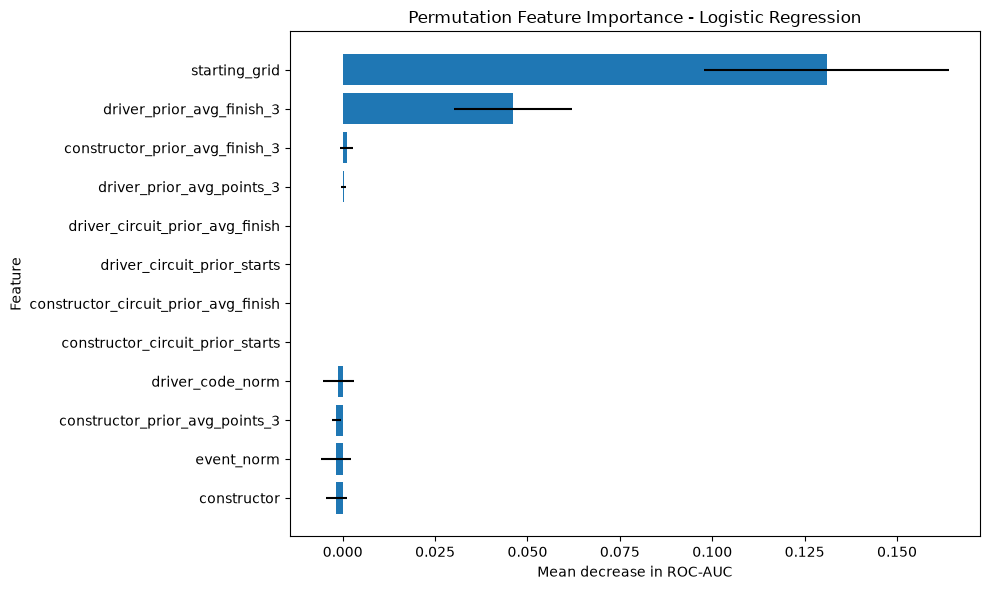


Analysing: Random Forest


,Feature,Importance Mean,Importance Std
0,starting_grid,0.050177,0.008384
9,driver_code_norm,0.006068,0.001701
10,constructor,0.002482,0.002012
3,driver_circuit_prior_avg_finish,0.000000,0.000000
8,constructor_circuit_prior_starts,0.000000,0.000000
7,constructor_circuit_prior_avg_finish,0.000000,0.000000
4,driver_circuit_prior_starts,0.000000,0.000000
5,constructor_prior_avg_finish_3,-0.000275,0.003283
6,constructor_prior_avg_points_3,-0.000437,0.004033
11,event_norm,-0.000607,0.000695


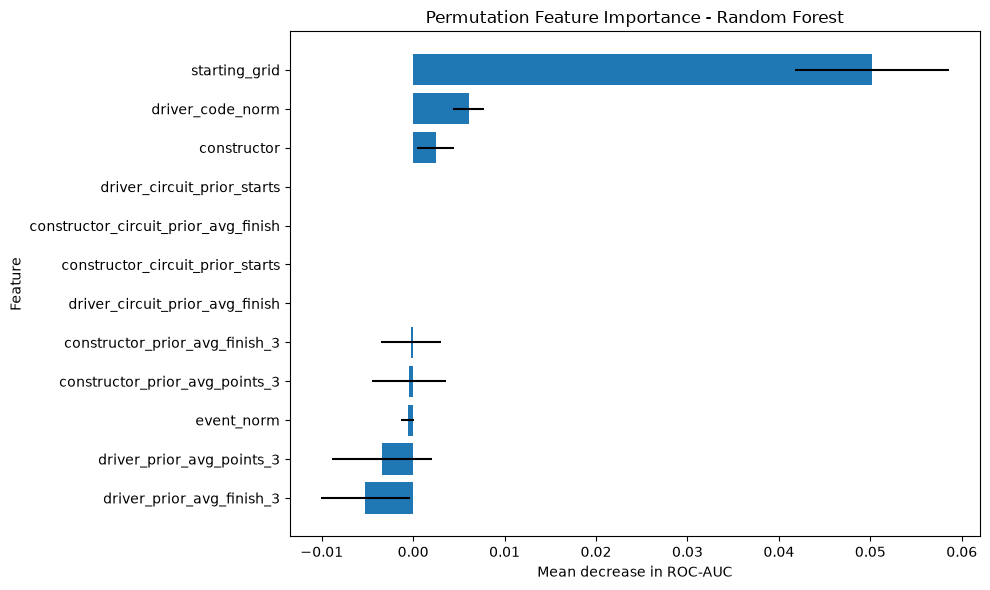


Analysing: Gradient Boosting


,Feature,Importance Mean,Importance Std
0,starting_grid,0.142063,0.013907
2,driver_prior_avg_points_3,0.019026,0.007060
9,driver_code_norm,0.002708,0.000719
3,driver_circuit_prior_avg_finish,0.000000,0.000000
10,constructor,0.000000,0.000000
4,driver_circuit_prior_starts,0.000000,0.000000
8,constructor_circuit_prior_starts,0.000000,0.000000
7,constructor_circuit_prior_avg_finish,0.000000,0.000000
5,constructor_prior_avg_finish_3,-0.000203,0.000462
11,event_norm,-0.000487,0.000474


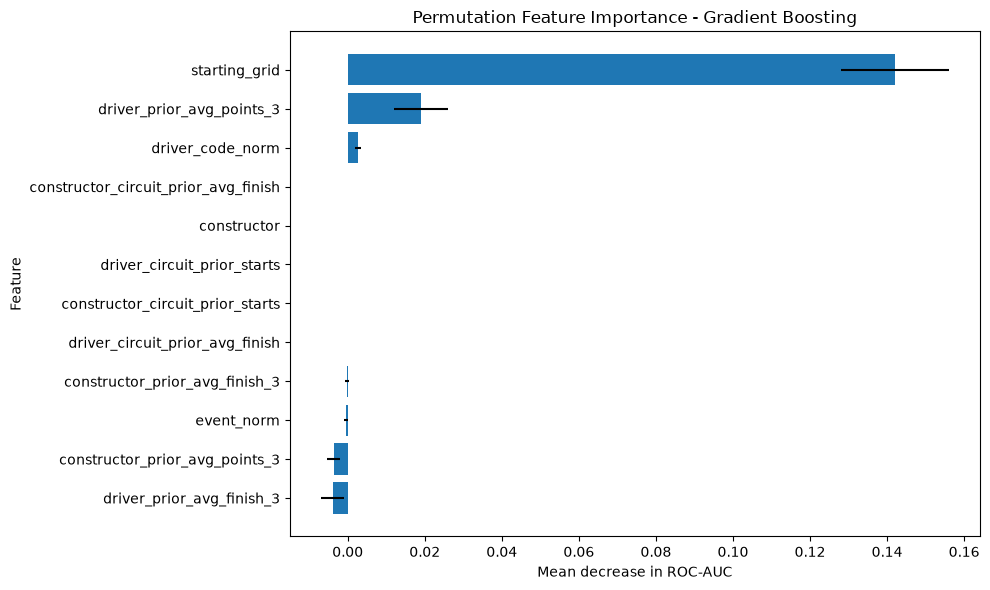

In [16]:

# ============================================================
# CELL 12: PERMUTATION FEATURE IMPORTANCE
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

feature_importance_results = {}

for model_name, model in models.items():

    print("\nAnalysing:", model_name)

    result = permutation_importance(
        model,
        X_val,
        y_val,
        scoring="roc_auc",
        n_repeats=30,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({

        "Feature": FEATURE_COLUMNS,

        "Importance Mean": result.importances_mean,

        "Importance Std": result.importances_std

    }).sort_values(
        "Importance Mean",
        ascending=False
    )

    feature_importance_results[model_name] = (
        importance_df
    )

    display(importance_df)

    # Visualise the top 12 features

    plt.figure(figsize=(10, 6))

    plot_df = importance_df.sort_values(
        "Importance Mean",
        ascending=True
    )

    plt.barh(
        plot_df["Feature"],
        plot_df["Importance Mean"],
        xerr=plot_df["Importance Std"]
    )

    plt.xlabel("Mean decrease in ROC-AUC")
    plt.ylabel("Feature")
    plt.title(
        f"Permutation Feature Importance - {model_name}"
    )

    plt.tight_layout()
    plt.show()


Cell 13 – Feature Availability Analysis

In [17]:

# ============================================================
# CELL 13: FEATURE AVAILABILITY AND VARIATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

feature_diagnostics = []

for col in FEATURE_COLUMNS:

    series = X_val[col]

    feature_diagnostics.append({

        "Feature": col,

        "Data Type": str(series.dtype),

        "Missing Values": series.isna().sum(),

        "Missing (%)": round(
            series.isna().mean() * 100, 2
        ),

        "Unique Values": series.nunique(),

        "Standard Deviation": (
            round(series.std(), 4)
            if pd.api.types.is_numeric_dtype(series)
            else np.nan
        )

    })

feature_diagnostics_df = pd.DataFrame(
    feature_diagnostics
)

print("==============================================")
print("FOR1SIGHT V2.8 - FEATURE DIAGNOSTICS")
print("==============================================")

display(
    feature_diagnostics_df.sort_values(
        "Missing (%)",
        ascending=False
    )
)

print("\nFeatures with no variation:")

print(
    feature_diagnostics_df[
        feature_diagnostics_df["Unique Values"] <= 1
    ]["Feature"].tolist()
)


FOR1SIGHT V2.8 - FEATURE DIAGNOSTICS


,Feature,Data Type,Missing Values,Missing (%),Unique Values,Standard Deviation
3,driver_circuit_prior_avg_finish,float64,129,26.93,20,5.7078
1,driver_prior_avg_finish_3,float64,3,0.63,57,4.5451
2,driver_prior_avg_points_3,float64,3,0.63,54,6.1161
0,starting_grid,float64,0,0.00,20,5.7619
4,driver_circuit_prior_starts,int64,0,0.00,2,0.4441
5,constructor_prior_avg_finish_3,float64,0,0.00,84,3.9093
6,constructor_prior_avg_points_3,float64,0,0.00,79,5.2655
7,constructor_circuit_prior_avg_finish,float64,0,0.00,36,4.9818
8,constructor_circuit_prior_starts,int64,0,0.00,1,0.0000
9,driver_code_norm,object,0,0.00,21,NaN



Features with no variation:
['constructor_circuit_prior_starts']


Cell 14 – Compare training and validation features

In [18]:

# ============================================================
# CELL 14: TRAINING VS VALIDATION FEATURE COMPARISON
# ============================================================

import pandas as pd
import numpy as np

comparison = []

for col in FEATURE_COLUMNS:

    train_series = X_train[col]
    val_series = X_val[col]

    comparison.append({

        "Feature": col,

        "2024 Missing (%)": round(
            train_series.isna().mean() * 100, 2
        ),

        "2025 Missing (%)": round(
            val_series.isna().mean() * 100, 2
        ),

        "2024 Unique Values": train_series.nunique(),

        "2025 Unique Values": val_series.nunique(),

        "2024 Std": round(
            train_series.std(), 4
        ) if pd.api.types.is_numeric_dtype(
            train_series
        ) else np.nan,

        "2025 Std": round(
            val_series.std(), 4
        ) if pd.api.types.is_numeric_dtype(
            val_series
        ) else np.nan

    })

comparison_df = pd.DataFrame(comparison)

print("=" * 65)
print("FOR1SIGHT V2.8 - TRAINING VS VALIDATION COMPARISON")
print("=" * 65)

display(comparison_df)

print("\nFEATURES CONSTANT IN TRAINING DATA:")

for col in FEATURE_COLUMNS:
    if X_train[col].nunique(dropna=True) <= 1:
        print(col)

print("\nFEATURES CONSTANT IN VALIDATION DATA:")

for col in FEATURE_COLUMNS:
    if X_val[col].nunique(dropna=True) <= 1:
        print(col)


FOR1SIGHT V2.8 - TRAINING VS VALIDATION COMPARISON


,Feature,2024 Missing (%),2025 Missing (%),2024 Unique Values,2025 Unique Values,2024 Std,2025 Std
0,starting_grid,0.00,0.00,20,20,5.7514,5.7619
1,driver_prior_avg_finish_3,5.02,0.63,63,57,4.8759,4.5451
2,driver_prior_avg_points_3,5.02,0.63,65,54,6.4123,6.1161
3,driver_circuit_prior_avg_finish,100.00,26.93,0,20,NaN,5.7078
4,driver_circuit_prior_starts,0.00,0.00,1,2,0.0000,0.4441
5,constructor_prior_avg_finish_3,4.18,0.00,86,84,4.4363,3.9093
6,constructor_prior_avg_points_3,4.18,0.00,82,79,5.8286,5.2655
7,constructor_circuit_prior_avg_finish,100.00,0.00,0,36,NaN,4.9818
8,constructor_circuit_prior_starts,0.00,0.00,1,1,0.0000,0.0000
9,driver_code_norm,0.00,0.00,24,21,NaN,NaN



FEATURES CONSTANT IN TRAINING DATA:
driver_circuit_prior_avg_finish
driver_circuit_prior_starts
constructor_circuit_prior_avg_finish
constructor_circuit_prior_starts

FEATURES CONSTANT IN VALIDATION DATA:
constructor_circuit_prior_starts


Cell 15 – Update feature selection

In [19]:

# ============================================================
# CELL 15: FINAL FEATURE SELECTION - V2.8
# ============================================================

# Retain only features with usable training information

FEATURE_COLUMNS = [

    # Numerical features
    "starting_grid",
    "driver_prior_avg_finish_3",
    "driver_prior_avg_points_3",
    "constructor_prior_avg_finish_3",
    "constructor_prior_avg_points_3",

    # Categorical features
    "driver_code_norm",
    "constructor",
    "event_norm"

]

# Update training and validation feature matrices
X_train = X_train[FEATURE_COLUMNS].copy()
X_val = X_val[FEATURE_COLUMNS].copy()

print("=" * 60)
print("FOR1SIGHT V2.8 - UPDATED FEATURE SELECTION")
print("=" * 60)

print("\nTotal selected features:", len(FEATURE_COLUMNS))

print("\nSelected features:")

for i, feature in enumerate(FEATURE_COLUMNS, 1):
    print(f"{i}. {feature}")

print("\nTraining dataset shape:", X_train.shape)
print("Validation dataset shape:", X_val.shape)

print("\nTraining missing values:")
print(X_train.isnull().sum())

print("\nValidation missing values:")
print(X_val.isnull().sum())

print("\nFeature selection completed successfully.")


FOR1SIGHT V2.8 - UPDATED FEATURE SELECTION

Total selected features: 8

Selected features:
1. starting_grid
2. driver_prior_avg_finish_3
3. driver_prior_avg_points_3
4. constructor_prior_avg_finish_3
5. constructor_prior_avg_points_3
6. driver_code_norm
7. constructor
8. event_norm

Training dataset shape: (478, 8)
Validation dataset shape: (479, 8)

Training missing values:
starting_grid                      0
driver_prior_avg_finish_3         24
driver_prior_avg_points_3         24
constructor_prior_avg_finish_3    20
constructor_prior_avg_points_3    20
driver_code_norm                   0
constructor                        0
event_norm                         0
dtype: int64

Validation missing values:
starting_grid                     0
driver_prior_avg_finish_3         3
driver_prior_avg_points_3         3
constructor_prior_avg_finish_3    0
constructor_prior_avg_points_3    0
driver_code_norm                  0
constructor                       0
event_norm                       

Next: Cell 16 – Rebuild the three ML pipelines

In [20]:

# ============================================================
# CELL 16: REBUILD V2.8 MACHINE LEARNING PIPELINES
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Separate numerical and categorical features

NUMERIC_FEATURES = [
    "starting_grid",
    "driver_prior_avg_finish_3",
    "driver_prior_avg_points_3",
    "constructor_prior_avg_finish_3",
    "constructor_prior_avg_points_3"
]

CATEGORICAL_FEATURES = [
    "driver_code_norm",
    "constructor",
    "event_norm"
]

# Numerical preprocessing

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, NUMERIC_FEATURES),
        ("categorical", categorical_preprocessor, CATEGORICAL_FEATURES)
    ]
)

# Three machine learning pipelines

models = {

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=80,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=5,
            random_state=42
        ))
    ])

}

print("=" * 60)
print("FOR1SIGHT V2.8 - UPDATED MODEL PIPELINES")
print("=" * 60)

for name, model in models.items():
    print(f"\n{name}")
    print(model)

print("\nAll three updated pipelines created successfully.")


FOR1SIGHT V2.8 - UPDATED MODEL PIPELINES

Logistic Regression
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['starting_grid',
                                                   'driver_prior_avg_finish_3',
                                                   'driver_prior_avg_points_3',
                                                   'constructor_prior_avg_finish_3',
                                                   'constructor_prior_avg_points_3']),
                                                 ('categorical',
                                  

Cell 17 – Retrain all three models

In [21]:

# ============================================================
# CELL 17: TRAIN UPDATED V2.8 MODELS
# ============================================================

import joblib

trained_models = {}

print("=" * 60)
print("FOR1SIGHT V2.8 - MODEL RETRAINING")
print("=" * 60)

print("\nTraining records:", len(X_train))
print("Winner records:", int(y_train.sum()))
print("Non-winner records:", int((y_train == 0).sum()))

for name, model in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", name.upper())
    print("=" * 60)

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "training completed successfully.")

print("\nAll three models retrained successfully.")


FOR1SIGHT V2.8 - MODEL RETRAINING

Training records: 478
Winner records: 24
Non-winner records: 454

TRAINING: LOGISTIC REGRESSION
Logistic Regression training completed successfully.

TRAINING: RANDOM FOREST
Random Forest training completed successfully.

TRAINING: GRADIENT BOOSTING
Gradient Boosting training completed successfully.

All three models retrained successfully.


Cell 18 – Save the updated models

In [22]:

# ============================================================
# CELL 18: SAVE UPDATED V2.8 MODELS
# ============================================================

from pathlib import Path

MODEL_DIR = Path(PROJECT_ROOT) / "models" / "v2_8"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_files = {
    "Logistic Regression": "logistic_regression_v2_8.joblib",
    "Random Forest": "random_forest_v2_8.joblib",
    "Gradient Boosting": "gradient_boosting_v2_8.joblib"
}

print("=" * 60)
print("FOR1SIGHT V2.8 - SAVING UPDATED MODELS")
print("=" * 60)

for name, model in trained_models.items():

    file_path = MODEL_DIR / model_files[name]

    joblib.dump(model, file_path)

    print(f"\nSaved {name}:")
    print(file_path)

print("\nAll updated models saved successfully.")


FOR1SIGHT V2.8 - SAVING UPDATED MODELS

Saved Logistic Regression:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\logistic_regression_v2_8.joblib

Saved Random Forest:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\random_forest_v2_8.joblib

Saved Gradient Boosting:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\gradient_boosting_v2_8.joblib

All updated models saved successfully.


In [23]:

# CELL 19A: VERIFY VALIDATION DATA

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nValidation objects available:")

for name in ["val_df", "df_val", "validation_df",
             "validation_data"]:

    if name in globals():
        print(name, "available")

print("\nValidation index matches:",
      X_val.index.equals(y_val.index))

print("\nAvailable validation columns:")
print(X_val.columns.tolist())


X_val shape: (479, 8)
y_val shape: (479,)

Validation objects available:
validation_df available

Validation index matches: True

Available validation columns:
['starting_grid', 'driver_prior_avg_finish_3', 'driver_prior_avg_points_3', 'constructor_prior_avg_finish_3', 'constructor_prior_avg_points_3', 'driver_code_norm', 'constructor', 'event_norm']


Cell 19 – Evaluate the three updated models

In [24]:

# ============================================================
# CELL 19: UPDATED MODEL VALIDATION - 2025
# ============================================================

import pandas as pd
import numpy as np

# 1. Recover validation metadata using matching indexes
val_meta = validation_df.loc[X_val.index].copy()

val_meta["actual_winner"] = np.asarray(y_val)

# 2. Identify race grouping column
if "event_id" in val_meta.columns:
    RACE_KEY = "event_id"

elif {"year", "round"}.issubset(val_meta.columns):
    val_meta["_race_key"] = (
        val_meta["year"].astype(str)
        + "_"
        + val_meta["round"].astype(str)
    )
    RACE_KEY = "_race_key"

else:
    RACE_KEY = "event_norm"

# 3. Validate race records
winner_counts = val_meta.groupby(RACE_KEY)[
    "actual_winner"
].sum()

invalid_races = winner_counts[winner_counts != 1]

if len(invalid_races) > 0:
    raise ValueError(
        f"Invalid winner counts in races: {invalid_races.to_dict()}"
    )

# 4. Calculate P1 baseline
p1_results = []

for race_id, race in val_meta.groupby(RACE_KEY):

    p1 = race[race["starting_grid"] == 1]

    if len(p1) == 1:
        p1_results.append(
            int(p1["actual_winner"].iloc[0])
        )

p1_accuracy = np.mean(p1_results) * 100

print("=" * 60)
print("FOR1SIGHT V2.8 - P1 BASELINE")
print("=" * 60)

print("Validation races:", len(p1_results))
print("P1 baseline accuracy:", round(p1_accuracy, 2), "%")

# 5. Evaluate all three models
evaluation_results = []
race_prediction_details = {}

for model_name, model in trained_models.items():

    print("\nEvaluating:", model_name)

    probabilities = model.predict_proba(X_val)

    winner_class_index = list(
        model.classes_
    ).index(1)

    scores = probabilities[:, winner_class_index]

    predictions = val_meta.copy()
    predictions["win_score"] = scores

    correct_top1 = 0
    correct_top3 = 0
    race_count = 0

    details = []

    for race_id, race in predictions.groupby(RACE_KEY):

        race = race.sort_values(
            "win_score",
            ascending=False
        )

        actual_winner = race.loc[
            race["actual_winner"] == 1,
            "driver_code"
        ].iloc[0]

        predicted_winner = race.iloc[0]["driver_code"]

        top_three = race.head(3)["driver_code"].tolist()

        top1_correct = predicted_winner == actual_winner
        top3_correct = actual_winner in top_three

        correct_top1 += int(top1_correct)
        correct_top3 += int(top3_correct)
        race_count += 1

        details.append({
            "race": race_id,
            "actual_winner": actual_winner,
            "predicted_winner": predicted_winner,
            "top_three": top_three,
            "top1_correct": top1_correct,
            "top3_correct": top3_correct
        })

    top1_accuracy = correct_top1 / race_count * 100
    top3_accuracy = correct_top3 / race_count * 100

    evaluation_results.append({

        "Model": model_name,
        "Top-1 Accuracy (%)": round(top1_accuracy, 2),
        "Top-3 Accuracy (%)": round(top3_accuracy, 2),
        "Correct Winners": correct_top1,
        "Validation Races": race_count,
        "P1 Baseline (%)": round(p1_accuracy, 2),
        "Improvement vs P1 (pp)": round(
            top1_accuracy - p1_accuracy, 2
        )

    })

    race_prediction_details[model_name] = details

# 6. Display comparison
evaluation_df = pd.DataFrame(evaluation_results)

print("\n" + "=" * 75)
print("UPDATED V2.8 MODEL EVALUATION RESULTS")
print("=" * 75)

display(
    evaluation_df.sort_values(
        "Top-1 Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)


FOR1SIGHT V2.8 - P1 BASELINE
Validation races: 24
P1 baseline accuracy: 66.67 %

Evaluating: Logistic Regression

Evaluating: Random Forest

Evaluating: Gradient Boosting

UPDATED V2.8 MODEL EVALUATION RESULTS


,Model,Top-1 Accuracy (%),Top-3 Accuracy (%),Correct Winners,Validation Races,P1 Baseline (%),Improvement vs P1 (pp)
0,Gradient Boosting,62.50,91.67,15,24,66.67,-4.17
1,Logistic Regression,45.83,83.33,11,24,66.67,-20.83
2,Random Forest,45.83,91.67,11,24,66.67,-20.83


Cell 20 – Prepare the 2026 final testing dataset

In [25]:

# ============================================================
# CELL 20: PREPARE 2026 FINAL TEST DATASET
# ============================================================

import pandas as pd
import numpy as np

# 1. Extract 2026 records
test_df = df[
    (df["year"] == 2026) &
    (df["model_training_eligible"] == True)
].copy()

# 2. Sort records consistently
test_df = test_df.sort_values(
    ["event_date", "round", "starting_grid"]
).reset_index(drop=True)

# 3. Verify required columns
required_test_columns = (
    FEATURE_COLUMNS
    + ["target", "event_id", "driver_code",
       "year", "round", "event_name"]
)

missing_columns = [
    col for col in required_test_columns
    if col not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# 4. Prepare features and target
X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df["target"].copy()

# 5. Verify chronological separation
assert set(test_df["year"].unique()) == {2026}

assert len(test_df) == 352
assert test_df["event_id"].nunique() == 16

assert len(X_test) == len(y_test)

# 6. Check duplicate driver-event records
duplicates = test_df.duplicated(
    subset=["event_id", "driver_code_norm"],
    keep=False
)

assert duplicates.sum() == 0, (
    "Duplicate driver-event records detected."
)

# 7. Verify exactly one winner per race
winner_check = (
    test_df.groupby("event_id")["target"]
    .sum()
)

invalid_races = winner_check[
    winner_check != 1
]

assert len(invalid_races) == 0, (
    f"Invalid winner counts: {invalid_races.to_dict()}"
)

# 8. Display dataset summary
print("=" * 60)
print("FOR1SIGHT V2.8 - 2026 FINAL TEST DATA")
print("=" * 60)

print("\nRecords:", len(test_df))
print("Unique races:", test_df["event_id"].nunique())

print("\nTarget distribution:")
print(y_test.value_counts())

print("\nMissing feature values:")
print(X_test.isnull().sum())

print("\nRace distribution:")
print(
    test_df.groupby(["round", "event_name"])
    .size()
)

print("\n2026 final testing dataset prepared successfully.")


FOR1SIGHT V2.8 - 2026 FINAL TEST DATA

Records: 352
Unique races: 16

Target distribution:
target
0    336
1     16
Name: count, dtype: int64

Missing feature values:
starting_grid                     0
driver_prior_avg_finish_3         1
driver_prior_avg_points_3         1
constructor_prior_avg_finish_3    4
constructor_prior_avg_points_3    4
driver_code_norm                  0
constructor                       0
event_norm                        0
dtype: int64

Race distribution:
round  event_name           
1      Australian Grand Prix    22
2      Chinese Grand Prix       22
3      Japanese Grand Prix      22
4      Miami Grand Prix         22
5      Canadian Grand Prix      22
6      Monaco Grand Prix        22
7      Barcelona Grand Prix     22
8      Austrian Grand Prix      22
9      British Grand Prix       22
10     Belgian Grand Prix       22
11     Hungarian Grand Prix     22
12     Dutch Grand Prix         22
13     Italian Grand Prix       22
14     Spanish Grand Prix   

Cell 21 – Evaluate the three models on 2026

In [26]:

# ============================================================
# CELL 21: 2026 FINAL MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

# 1. Prepare prediction metadata
test_meta = test_df.copy()

# 2. Calculate P1 baseline
p1_correct = 0
p1_total = 0

for event_id, race in test_meta.groupby("event_id"):

    p1_driver = race[
        race["starting_grid"] == 1
    ]

    if len(p1_driver) != 1:
        raise ValueError(
            f"Expected exactly one P1 driver in {event_id}"
        )

    actual_winner = race.loc[
        race["target"] == 1,
        "driver_code"
    ].iloc[0]

    predicted_winner = p1_driver[
        "driver_code"
    ].iloc[0]

    p1_correct += int(
        predicted_winner == actual_winner
    )

    p1_total += 1

p1_accuracy = p1_correct / p1_total

# 3. Evaluate all three models
final_test_results = []
final_test_predictions = {}
final_race_details = {}

for model_name, model in trained_models.items():

    print("\nEvaluating:", model_name)

    probabilities = model.predict_proba(
        X_test
    )

    winner_index = list(
        model.classes_
    ).index(1)

    scores = probabilities[:, winner_index]

    predictions = test_meta.copy()
    predictions["win_probability"] = scores

    top1_correct = 0
    top3_correct = 0

    race_details = []

    # Race-level evaluation
    for event_id, race in predictions.groupby("event_id"):

        ranked = race.sort_values(
            "win_probability",
            ascending=False
        ).reset_index(drop=True)

        actual_winner = race.loc[
            race["target"] == 1,
            "driver_code"
        ].iloc[0]

        predicted_winner = (
            ranked.iloc[0]["driver_code"]
        )

        top_three = (
            ranked.head(3)["driver_code"].tolist()
        )

        top1 = predicted_winner == actual_winner
        top3 = actual_winner in top_three

        top1_correct += int(top1)
        top3_correct += int(top3)

        race_details.append({

            "Round": race["round"].iloc[0],

            "Grand Prix": race["event_name"].iloc[0],

            "Actual Winner": actual_winner,

            "Predicted Winner": predicted_winner,

            "Top 3": ", ".join(top_three),

            "Correct Top 1": top1,

            "Winner in Top 3": top3

        })

    total_races = predictions["event_id"].nunique()

    # Driver-level classification metrics
    final_test_results.append({

        "Model": model_name,

        "Top-1 Accuracy (%)":
            round(top1_correct / total_races * 100, 2),

        "Top-3 Accuracy (%)":
            round(top3_correct / total_races * 100, 2),

        "ROC-AUC":
            round(
                roc_auc_score(y_test, scores), 4
            ),

        "PR-AUC":
            round(
                average_precision_score(y_test, scores), 4
            ),

        "Log Loss":
            round(
                log_loss(y_test, scores, labels=[0, 1]), 4
            ),

        "Brier Score":
            round(
                brier_score_loss(y_test, scores), 4
            ),

        "Correct Winners": top1_correct,

        "Total Races": total_races

    })

    final_test_predictions[model_name] = scores

    final_race_details[model_name] = pd.DataFrame(
        race_details
    )

# 4. Display final evaluation
final_test_df = pd.DataFrame(final_test_results)

print("\n" + "=" * 75)
print("FOR1SIGHT V2.8 - 2026 FINAL TEST RESULTS")
print("=" * 75)

display(
    final_test_df.sort_values(
        "Top-1 Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

# 5. Display P1 baseline
print("\nP1 STARTING-GRID BASELINE")
print("=" * 45)

print("Correct predictions:", p1_correct)
print("Total races:", p1_total)

print(
    "P1 Top-1 Accuracy:",
    round(p1_accuracy * 100, 2),
    "%"
)

# 6. Compare models against P1
final_comparison = final_test_df[
    ["Model", "Top-1 Accuracy (%)", "Top-3 Accuracy (%)"]
].copy()

final_comparison["P1 Baseline (%)"] = round(
    p1_accuracy * 100, 2
)

final_comparison["Improvement vs P1 (pp)"] = (
    final_comparison["Top-1 Accuracy (%)"]
    - p1_accuracy * 100
).round(2)

print("\nFINAL MODEL VS P1 COMPARISON")

display(final_comparison)



Evaluating: Logistic Regression

Evaluating: Random Forest

Evaluating: Gradient Boosting

FOR1SIGHT V2.8 - 2026 FINAL TEST RESULTS


,Model,Top-1 Accuracy (%),Top-3 Accuracy (%),ROC-AUC,PR-AUC,Log Loss,Brier Score,Correct Winners,Total Races
0,Gradient Boosting,75.0,93.75,0.9735,0.6236,0.0855,0.0259,12,16
1,Random Forest,50.0,75.00,0.9405,0.4918,0.2246,0.0700,8,16
2,Logistic Regression,37.5,75.00,0.9187,0.4422,0.2461,0.0848,6,16



P1 STARTING-GRID BASELINE
Correct predictions: 11
Total races: 16
P1 Top-1 Accuracy: 68.75 %

FINAL MODEL VS P1 COMPARISON


,Model,Top-1 Accuracy (%),Top-3 Accuracy (%),P1 Baseline (%),Improvement vs P1 (pp)
0,Logistic Regression,37.5,75.00,68.75,-31.25
1,Random Forest,50.0,75.00,68.75,-18.75
2,Gradient Boosting,75.0,93.75,68.75,6.25


Cell 22 – Examine individual race predictions

In [27]:

# ============================================================
# CELL 22: INDIVIDUAL 2026 RACE PREDICTIONS
# ============================================================

for model_name, details in final_race_details.items():

    print("\n" + "=" * 70)
    print("RACE PREDICTIONS:", model_name)
    print("=" * 70)

    display(
        details[
            [
                "Round",
                "Grand Prix",
                "Actual Winner",
                "Predicted Winner",
                "Top 3",
                "Correct Top 1",
                "Winner in Top 3"
            ]
        ]
    )

    correct = details["Correct Top 1"].sum()
    total = len(details)

    print(
        f"Correct predictions: {correct}/{total}"
    )



RACE PREDICTIONS: Logistic Regression


,Round,Grand Prix,Actual Winner,Predicted Winner,Top 3,Correct Top 1,Winner in Top 3
0,1,Australian Grand Prix,RUS,RUS,"RUS, LEC, ANT",True,True
1,8,Austrian Grand Prix,RUS,HAM,"HAM, VER, ANT",False,False
2,15,Azerbaijan Grand Prix,RUS,RUS,"RUS, NOR, HAD",True,True
3,7,Barcelona Grand Prix,HAM,ANT,"ANT, HAM, VER",False,True
4,10,Belgian Grand Prix,ANT,VER,"VER, RUS, HAM",False,False
5,9,British Grand Prix,LEC,HAM,"HAM, ANT, RUS",False,False
6,5,Canadian Grand Prix,ANT,ANT,"ANT, RUS, HAM",True,True
7,2,Chinese Grand Prix,ANT,VER,"VER, RUS, ANT",False,True
8,12,Dutch Grand Prix,NOR,NOR,"NOR, LEC, HAM",True,True
9,11,Hungarian Grand Prix,NOR,LEC,"LEC, VER, NOR",False,True


Correct predictions: 6/16

RACE PREDICTIONS: Random Forest


,Round,Grand Prix,Actual Winner,Predicted Winner,Top 3,Correct Top 1,Winner in Top 3
0,1,Australian Grand Prix,RUS,RUS,"RUS, VER, ANT",True,True
1,8,Austrian Grand Prix,RUS,HAM,"HAM, ANT, VER",False,False
2,15,Azerbaijan Grand Prix,RUS,RUS,"RUS, NOR, PIA",True,True
3,7,Barcelona Grand Prix,HAM,HAM,"HAM, ANT, VER",True,True
4,10,Belgian Grand Prix,ANT,RUS,"RUS, VER, HAM",False,False
5,9,British Grand Prix,LEC,ANT,"ANT, HAM, RUS",False,False
6,5,Canadian Grand Prix,ANT,RUS,"RUS, ANT, HAM",False,True
7,2,Chinese Grand Prix,ANT,RUS,"RUS, ANT, VER",False,True
8,12,Dutch Grand Prix,NOR,NOR,"NOR, ANT, HAM",True,True
9,11,Hungarian Grand Prix,NOR,LEC,"LEC, NOR, HAM",False,True


Correct predictions: 8/16

RACE PREDICTIONS: Gradient Boosting


,Round,Grand Prix,Actual Winner,Predicted Winner,Top 3,Correct Top 1,Winner in Top 3
0,1,Australian Grand Prix,RUS,RUS,"RUS, ANT, VER",True,True
1,8,Austrian Grand Prix,RUS,RUS,"RUS, HAM, LEC",True,True
2,15,Azerbaijan Grand Prix,RUS,RUS,"RUS, LEC, NOR",True,True
3,7,Barcelona Grand Prix,HAM,RUS,"RUS, HAM, ANT",False,True
4,10,Belgian Grand Prix,ANT,ANT,"ANT, HAM, VER",True,True
5,9,British Grand Prix,LEC,ANT,"ANT, HAM, LEC",False,True
6,5,Canadian Grand Prix,ANT,RUS,"RUS, ANT, HAM",False,True
7,2,Chinese Grand Prix,ANT,ANT,"ANT, RUS, NOR",True,True
8,12,Dutch Grand Prix,NOR,NOR,"NOR, RUS, HAM",True,True
9,11,Hungarian Grand Prix,NOR,NOR,"NOR, LEC, HAM",True,True


Correct predictions: 12/16


Cell 27 – Prepare combined training data

In [28]:

# ============================================================
# CELL 27: PREPARE FINAL DEPLOYMENT TRAINING DATA
# ============================================================

# Combine 2024 and 2025 only
deployment_df = df[
    df["year"].isin([2024, 2025])
    & (df["model_training_eligible"] == True)
].copy()

deployment_df = deployment_df.sort_values(
    ["year", "event_date", "round", "starting_grid"]
).reset_index(drop=True)

# Prepare features and target
X_deployment = deployment_df[
    FEATURE_COLUMNS
].copy()

y_deployment = deployment_df[
    "target"
].copy()

# Validation checks
assert set(deployment_df["year"].unique()) == {2024, 2025}
assert len(deployment_df) == 957

assert X_deployment.shape[1] == 8
assert len(X_deployment) == len(y_deployment)

winner_check = deployment_df.groupby(
    "event_id"
)["target"].sum()

assert (winner_check == 1).all()

print("=" * 60)
print("FOR1SIGHT V2.8 - DEPLOYMENT DATA")
print("=" * 60)

print("Records:", len(deployment_df))
print("Features:", len(FEATURE_COLUMNS))
print("Races:", deployment_df["event_id"].nunique())

print("\nSeason distribution:")
print(deployment_df["year"].value_counts().sort_index())

print("\nWinner distribution:")
print(y_deployment.value_counts())

print("\nMissing values:")
print(X_deployment.isnull().sum())

print("\nDeployment training data prepared.")


FOR1SIGHT V2.8 - DEPLOYMENT DATA
Records: 957
Features: 8
Races: 48

Season distribution:
year
2024    478
2025    479
Name: count, dtype: int64

Winner distribution:
target
0    909
1     48
Name: count, dtype: int64

Missing values:
starting_grid                      0
driver_prior_avg_finish_3         27
driver_prior_avg_points_3         27
constructor_prior_avg_finish_3    20
constructor_prior_avg_points_3    20
driver_code_norm                   0
constructor                        0
event_norm                         0
dtype: int64

Deployment training data prepared.


Cell 28 – Train final deployment models

In [29]:

# ============================================================
# CELL 28: TRAIN FINAL DEPLOYMENT MODELS
# ============================================================

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

# Create fresh model pipelines
deployment_models = {}

print("=" * 65)
print("FOR1SIGHT V2.8 - FINAL DEPLOYMENT TRAINING")
print("=" * 65)

print("\nTraining records:", len(X_deployment))
print("Race events:", deployment_df["event_id"].nunique())
print("Winner records:", int(y_deployment.sum()))
print("Non-winner records:", int((y_deployment == 0).sum()))

# Train each model
for model_name, original_model in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", model_name.upper())
    print("=" * 60)

    # Create a fresh pipeline
    deployment_model = clone(original_model)

    # Gradient Boosting uses balanced sample weights
    if model_name == "Gradient Boosting":

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_deployment
        )

        deployment_model.fit(
            X_deployment,
            y_deployment,
            classifier__sample_weight=sample_weights
        )

    else:

        deployment_model.fit(
            X_deployment,
            y_deployment
        )

    deployment_models[model_name] = deployment_model

    print(model_name, "training completed.")

print("\n" + "=" * 65)
print("FINAL DEPLOYMENT TRAINING COMPLETED")
print("=" * 65)

print("Models trained:", len(deployment_models))
print("Training seasons: 2024 and 2025")
print("2026 final test data was not used.")


FOR1SIGHT V2.8 - FINAL DEPLOYMENT TRAINING

Training records: 957
Race events: 48
Winner records: 48
Non-winner records: 909

TRAINING: LOGISTIC REGRESSION
Logistic Regression training completed.

TRAINING: RANDOM FOREST
Random Forest training completed.

TRAINING: GRADIENT BOOSTING
Gradient Boosting training completed.

FINAL DEPLOYMENT TRAINING COMPLETED
Models trained: 3
Training seasons: 2024 and 2025
2026 final test data was not used.


Cell 29 – Save final deployment models

In [30]:

# ============================================================
# CELL 29: SAVE FINAL DEPLOYMENT MODELS
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path(PROJECT_ROOT) / "models" / "v2_8"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

deployment_model_files = {

    "Logistic Regression":
        "logistic_regression_deployment_v2_8.joblib",

    "Random Forest":
        "random_forest_deployment_v2_8.joblib",

    "Gradient Boosting":
        "gradient_boosting_deployment_v2_8.joblib"

}

saved_deployment_models = {}

print("=" * 65)
print("FOR1SIGHT V2.8 - SAVING DEPLOYMENT MODELS")
print("=" * 65)

for model_name, model in deployment_models.items():

    filename = deployment_model_files[model_name]

    model_path = MODEL_DIR / filename

    joblib.dump(model, model_path)

    saved_deployment_models[model_name] = str(model_path)

    print(f"\n{model_name}")
    print("Saved:", model_path)

print("\nAll deployment models saved successfully.")


FOR1SIGHT V2.8 - SAVING DEPLOYMENT MODELS

Logistic Regression
Saved: c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\logistic_regression_deployment_v2_8.joblib

Random Forest
Saved: c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\random_forest_deployment_v2_8.joblib

Gradient Boosting
Saved: c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\gradient_boosting_deployment_v2_8.joblib

All deployment models saved successfully.


Cell 30 – Create model metadata

In [31]:

# ============================================================
# CELL 30: CREATE DEPLOYMENT MODEL METADATA
# ============================================================

import json
from datetime import datetime, timezone

metadata = {

    "project": "For1Sight",

    "version": "V2.8",

    "model_purpose": "F1 Race Winner Classification",

    "deployment_training_seasons": [2024, 2025],

    "training_records": len(X_deployment),

    "training_races": int(
        deployment_df["event_id"].nunique()
    ),

    "feature_count": len(FEATURE_COLUMNS),

    "features": FEATURE_COLUMNS,

    "target": "target",

    "target_description": "1 = Race Winner, 0 = Non-Winner",

    "algorithms": {

        "Logistic Regression":
            deployment_model_files["Logistic Regression"],

        "Random Forest":
            deployment_model_files["Random Forest"],

        "Gradient Boosting":
            deployment_model_files["Gradient Boosting"]

    },

    "preprocessing": {

        "numeric_imputation": "median",

        "numeric_scaling": "StandardScaler",

        "categorical_imputation": "most_frequent",

        "categorical_encoding": "OneHotEncoder",

        "unknown_categories": "ignore"

    },

    "final_test_season": 2026,

    "final_test_records": 352,

    "final_test_races": 16,

    "final_test_models_trained_on_2024_only": True,

    "deployment_training_uses_2026": False,

    "calibration_verified": False,

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat()

}

metadata_path = MODEL_DIR / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:

    json.dump(metadata, file, indent=4)

print("Model metadata saved:")
print(metadata_path)

print("\nMetadata creation completed.")


Model metadata saved:
c:\Users\ayepd\Desktop\For1Sight Project\models\v2_8\model_metadata.json

Metadata creation completed.


Cell 31 – Verify the saved models

In [32]:

# ============================================================
# CELL 31: VERIFY DEPLOYMENT MODEL FILES
# ============================================================

import joblib
import numpy as np

verified_models = {}

# Use a small sample of the deployment dataset
sample_input = X_deployment.head(10).copy()

print("=" * 65)
print("FOR1SIGHT V2.8 - DEPLOYMENT MODEL VERIFICATION")
print("=" * 65)

for model_name, filename in deployment_model_files.items():

    model_path = MODEL_DIR / filename

    # Load saved model
    loaded_model = joblib.load(model_path)

    # Generate predictions
    probabilities = loaded_model.predict_proba(
        sample_input
    )

    winner_index = list(
        loaded_model.classes_
    ).index(1)

    winner_scores = probabilities[:, winner_index]

    # Verify probability outputs
    assert len(winner_scores) == 10

    assert np.isfinite(winner_scores).all()

    assert (
        (winner_scores >= 0)
        & (winner_scores <= 1)
    ).all()

    verified_models[model_name] = loaded_model

    print("\n", model_name)

    print("File exists:", model_path.exists())

    print("Predictions generated:", len(winner_scores))

    print(
        "Sample winner probabilities:",
        np.round(winner_scores[:5], 4)
    )

print("\n" + "=" * 65)
print("ALL DEPLOYMENT MODELS VERIFIED SUCCESSFULLY")
print("=" * 65)


FOR1SIGHT V2.8 - DEPLOYMENT MODEL VERIFICATION

 Logistic Regression
File exists: True
Predictions generated: 10
Sample winner probabilities: [0.8412 0.3052 0.2482 0.2018 0.034 ]

 Random Forest
File exists: True
Predictions generated: 10
Sample winner probabilities: [0.5189 0.2524 0.2399 0.1296 0.1488]

 Gradient Boosting
File exists: True
Predictions generated: 10
Sample winner probabilities: [0.9262 0.1891 0.145  0.0523 0.0179]

ALL DEPLOYMENT MODELS VERIFIED SUCCESSFULLY
